# 01 · Pretraining a Transformer Language Model: What a Base Model Knows, and What It Won't Do

## Overview

*Post-training* is everything done to a model **after** large-scale next-token pretraining: supervised
fine-tuning, preference learning, reinforcement learning, distillation. This series follows the history of
those methods for **transformers** (notebooks 01-05), **diffusion models** (06-08) and **diffusion
transformers** (09-10). Each method appears *because the previous one fails at something measurable*,
and a shared scorecard (`results/scorecard.csv`) makes those failures visible.

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| **01** | **Pretraining** | **Next-token prediction on raw text** | **Knowledge: the model *can* add** | **Doesn't follow instructions** |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Every model here is small enough to train on a laptop CPU in minutes. That is a deliberate trade: we lose
the headline numbers of the papers, but we gain something real labs never have, a **programmatic ground
truth**. Our language task (adding numbers, asked in plain English) has a verifier, so we can measure
exactly when a learned reward model is being fooled, which is impossible with human preferences at scale.

In this notebook we pretrain a ~0.8M-parameter character-level GPT on synthetic "web text" and then ask
the question every post-training paper starts from: *the base model clearly knows things, so why can't
we just ask it?*

## Learning objectives

1. Write down the next-token objective and explain causal self-attention with a pre-LayerNorm transformer block.
2. Pretrain a small GPT with AdamW, warmup and cosine decay, and read its loss curve.
3. Separate **knowledge** (can the model add?) from **behaviour** (does it answer when asked?) with two measurements.
4. Relate a tiny scaling experiment to the scaling laws of [Kaplan et al., 2020](https://arxiv.org/abs/2001.08361) and [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556).

**Runtime:** about 7 minutes on a laptop CPU (pretraining is ~4 minutes of that).

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
sys.path.insert(0, ".")
from ptlib import tasks, lm, align, metrics, set_seed
torch.set_num_threads(min(8, torch.get_num_threads()))
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1 | threads 8


## 1. A small world with a ground truth

Real pretraining corpora are scraped web text. Ours is generated, but it has the same two ingredients:
**facts** written in a few different styles, and a lot of **unrelated text**. The facts are sums of 2-digit
numbers (and a smaller number of 3-digit sums). The unrelated text comes from a toy grammar.

Two design choices matter for the rest of the series:

* **400 two-digit and 400 three-digit problems are held out** of all training data (`tasks.TEST_2D`, `tasks.TEST_3D`). Every accuracy we report is on these.
* **The chat format never appears in pretraining.** Instructions look like `Q: what is 23 plus 45?\nA:`, the way users talk to assistants. Pretraining text writes facts as `23+45=68` or `the sum of 23 and 45 is 68.`.

In [2]:
text = tasks.pretraining_corpus()
print(f"corpus: {len(text):,} characters, {text.count(chr(10)):,} lines, vocabulary of {tasks.VOCAB_SIZE} characters")
print("-" * 60)
print(text[:420])
print("-" * 60)
print("an instruction prompt, as later notebooks will ask it:")
print(repr(tasks.make_prompt(23, 45, template=0)))
print("does 'Q:' ever occur in pretraining?", "Q:" in text)

corpus: 1,599,389 characters, 60,000 lines, vocabulary of 49 characters
------------------------------------------------------------
she counted 25 26 27 28.
47+49=96
a house and a river went to the green river.
she counted 50 51 52 53 54 55.
she counted 1 2 3 4.
the sum of 58 and 17 is 75.
87+71=158
a fox and a cat went to the new river.
80+20=100
the happy river likes the quiet child.
there are 48 cars near the bird.
she counted 75 76 77 78 79.
40+92=132
a house and a bird went to the old river.
746+900=1646
the sum of 53 and 16 is 69.
the sum o
------------------------------------------------------------
an instruction prompt, as later notebooks will ask it:
'Q: what is 23 plus 45?\nA:'
does 'Q:' ever occur in pretraining? False


## 2. The model: a pre-LayerNorm GPT

A decoder-only transformer ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) maps a sequence of tokens $x_1..x_T$ to a distribution over
the next token at every position. Each block applies **causal self-attention** and an MLP, each wrapped in
a residual connection with LayerNorm *before* the sublayer ("pre-LN", which trains stably without
careful warmup; [Xiong et al., 2020](https://arxiv.org/abs/2002.04745)):

$$h \leftarrow h + \mathrm{Attn}(\mathrm{LN}(h)), \qquad h \leftarrow h + \mathrm{MLP}(\mathrm{LN}(h)),$$
$$\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V, \quad M_{ij} = \begin{cases}0 & j \le i \\ -\infty & j > i\end{cases}$$

The mask $M$ is what makes the model *causal*: position $i$ cannot look at the future, so it can be
trained on every position of a sequence at once and later used to generate one token at a time.
Here is the whole block from `ptlib/lm.py`:

In [3]:
print(inspect.getsource(lm.Block))
model = lm.GPT()
print(f"GPT config {model.cfg}: {lm.n_params(model):,} parameters")

class Block(nn.Module):
    def __init__(self, d, n_head):
        super().__init__()
        self.n_head = n_head
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.fc1, self.fc2 = nn.Linear(d, 4 * d), nn.Linear(4 * d, d)

    def forward(self, x, attn_mask, cache=None):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(D, dim=-1)
        q, k, v = (t.view(B, T, self.n_head, D // self.n_head).transpose(1, 2) for t in (q, k, v))
        if cache is not None:                      # key/value cache for fast generation
            if "k" in cache:
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        h = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask)
        x = x + self.proj(h.transpose(1, 2).reshape(B, T, D))
        return x + self.fc2(F.gelu(self.fc1(self.ln2(x))))

GPT config {'vo

## 3. Pretraining: predict the next character

The objective is maximum likelihood of the corpus, one token at a time:
$$\mathcal{L}_{\text{LM}}(\theta) = -\,\mathbb{E}_{x \sim \mathcal{D}} \sum_{t} \log p_\theta(x_t \mid x_{<t}).$$

The training loop is five lines, and **every post-training method in this series is a change to one of
them**: SFT changes *which tokens* count in the loss, RLHF changes the loss into a reward-weighted one, and
DPO replaces it with a comparison between two sequences. The loop below runs for a few hundred steps
so you can see it; the full run uses the same loop through `lm.pretrain` (AdamW, linear warmup, cosine decay,
gradient clipping).

In [4]:
set_seed(0)
demo = lm.GPT()
opt = torch.optim.AdamW(demo.parameters(), lr=1e-3)
batches = lm.lm_batches(text, batch=64, block=64, rng=np.random.default_rng(0))
for step in range(200):
    x, y = next(batches)                                              # (64, 64) windows of text, y = x shifted by one
    loss = F.cross_entropy(demo(x).view(-1, tasks.VOCAB_SIZE), y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0 or step == 199:
        print(f"step {step:3d}  loss {loss.item():.3f}   (uniform guessing = ln {tasks.VOCAB_SIZE} = {np.log(tasks.VOCAB_SIZE):.2f})")

step   0  loss 3.953   (uniform guessing = ln 49 = 3.89)
step  50  loss 1.980   (uniform guessing = ln 49 = 3.89)
step 100  loss 1.306   (uniform guessing = ln 49 = 3.89)
step 150  loss 0.934   (uniform guessing = ln 49 = 3.89)
step 199  loss 0.736   (uniform guessing = ln 49 = 3.89)


Now the full pretraining run (3,000 steps of 64 × 64 characters, about 12 passes over the corpus). The result is saved to `checkpoints/base_lm.pt`, and every later notebook starts from it.

step   500  loss 1.273  (39s)
step  1000  loss 0.570  (79s)
step  1500  loss 0.508  (120s)
step  2000  loss 0.489  (161s)
step  2500  loss 0.482  (202s)
step  3000  loss 0.477  (243s)
pretraining took 243s


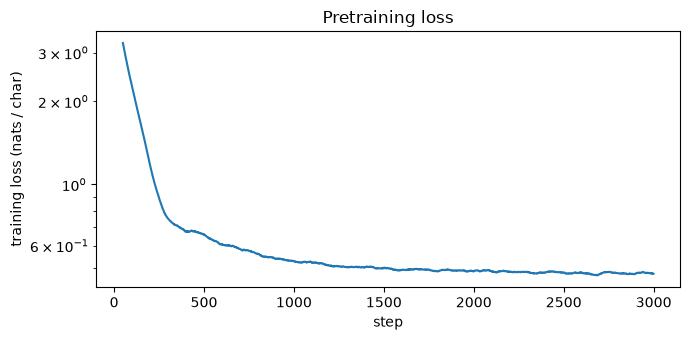

In [5]:
set_seed(0)
base = lm.GPT()
t0 = time.time()
losses = lm.pretrain(base, text, **lm.PRETRAIN_KW, log_every=500)
print(f"pretraining took {time.time() - t0:.0f}s")
lm.save(base, "base_lm")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(pd.Series(losses).rolling(50).mean())
ax.set_xlabel("step"); ax.set_ylabel("training loss (nats / char)"); ax.set_yscale("log")
ax.set_title("Pretraining loss"); fig.tight_layout(); plt.show()

## 4. What the base model knows

Ask the model a held-out problem **the way pretraining text writes it**, `23+45=`, and let it complete
greedily. This measures *knowledge*. Because the 400 held-out pairs never appeared anywhere in training,
a high score means the model learned the addition algorithm rather than memorising facts.

In [6]:
know = {
    "2-digit, 'a+b='": align.completion_accuracy(base, tasks.TEST_2D),
    "2-digit, 'the sum of a and b is'": align.completion_accuracy(base, tasks.TEST_2D, "the sum of {a} and {b} is"),
    "3-digit, 'a+b='": align.completion_accuracy(base, tasks.TEST_3D),
}
for k, v in know.items():
    print(f"{k:38s} {v:.1%}")
print()
for p in ["57+38=", "the sum of 61 and 29 is", "the red fox", "she counted 7"]:
    print(repr(p), "->", repr(lm.generate(base, [p], greedy=True)[0]))

2-digit, 'a+b='                        91.2%
2-digit, 'the sum of a and b is'       100.0%
3-digit, 'a+b='                        41.2%

'57+38=' -> '95\n'
'the sum of 61 and 29 is' -> ' 90.\n'
'the red fox' -> '.\n'
'she counted 7' -> ' 8 9 10 11.\n'


## 5. What the base model won't do

Now ask the same held-out problems **in the chat format**. The verifier (`tasks.gold_reward`) accepts
only a well-formed answer on the first line, either `" 68"` or `" the answer is 68."`, so this measures
*behaviour*.

In [7]:
chat = align.evaluate(base)
print({k: round(v, 3) for k, v in chat.items()})
rng = np.random.default_rng(0)
for a, b in tasks.TEST_2D[:5]:
    p = tasks.make_prompt(a, b, rng=rng)
    print(repr(p), "->", repr(lm.generate(base, [p], greedy=True)[0]))

{'greedy_acc': 0.0, 'sampled_acc': 0.0, 'well_formed': 0.0, 'sentence_style': 0.0, 'mean_len': 20.023}
'Q: 39+79=?\nA:' -> '140848=108=1088\n'
'Q: add 91 and 45.\nA:' -> ' rietroume fox follows t'
'Q: add 47 and 18.\nA:' -> ' rietroume w follows the'
'Q: what is 21 plus 22?\nA:' -> ' chiet fox follows the b'
'Q: what is 71 plus 96?\nA:' -> ' chiet foum 22 wat ches '


This is the gap post-training exists to close. The model **knows** how to add (section 4), but given a
question it does what pretraining taught it to do: it continues the document. An unfamiliar prefix like
`Q:` gets continued as if it were the start of an ordinary sentence. Large base models behave the
same way, because their objective is to predict the next token of a web page, not to follow the user's instructions.
That mismatch is the stated motivation for instruction tuning and RLHF in [Ouyang et al., 2022](https://arxiv.org/abs/2203.02155).

## 6. A two-minute scaling experiment

Why pretrain big models at all? [Kaplan et al., 2020](https://arxiv.org/abs/2001.08361) found that loss falls as a smooth power law in model
size, data and compute. [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556) (Chinchilla) then showed that, for a fixed compute budget,
parameters and training tokens should grow together. We can see the first effect in miniature: three
widths, the same 600 steps.

,d_model,params,held_out_loss,add_2d,seconds
0,32,54496,0.982,0.000,23.918
1,64,207296,0.648,0.020,31.601
2,128,807808,0.591,0.015,50.394


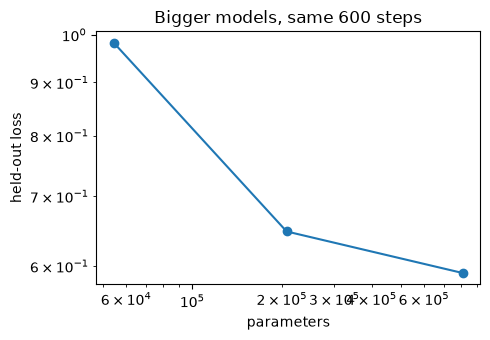

In [8]:
scale = []
for d in [32, 64, 128]:
    set_seed(0)
    m = lm.GPT(d=d, n_head=4)
    t0 = time.time()
    lm.pretrain(m, text, steps=600, batch=64, lr=2e-3, warmup=50, log_every=0)
    scale.append(dict(d_model=d, params=lm.n_params(m), held_out_loss=lm.corpus_loss(m, tasks.pretraining_corpus(4000, seed=7)),
                      add_2d=align.completion_accuracy(m, tasks.TEST_2D[:200]), seconds=time.time() - t0))
scale = pd.DataFrame(scale)
display(scale.round(3))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.loglog(scale.params, scale.held_out_loss, "o-")
ax.set_xlabel("parameters"); ax.set_ylabel("held-out loss"); ax.set_title("Bigger models, same 600 steps")
fig.tight_layout(); plt.show()

Read this as an illustration, not a scaling law: three points, one seed, and a short training budget. The
loss does fall with model size at a fixed step count, as in [Kaplan et al., 2020](https://arxiv.org/abs/2001.08361). Loss is not the whole story,
though. After 600 steps **none** of the three models can add yet (0–2% on held-out sums); the full run in
section 3 needed several times more steps. A capability can lag behind a smoothly falling loss.

## 7. The scorecard

Each notebook appends its models to `results/scorecard.csv`. The base model sets the reference point:
it knows the arithmetic but scores zero as an assistant.

In [9]:
row = dict(model="base (pretrained)", family="lm", **chat,
           completion_acc_2d=know["2-digit, 'a+b='"], completion_acc_3d=know["3-digit, 'a+b='"])
metrics.append_rows([row], "01_pretraining")
display(metrics.load_scorecard().query("notebook == '01_pretraining'").round(3))

,notebook,model,family,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,completion_acc_2d,completion_acc_3d
0,01_pretraining,base (pretrained),lm,0.0,0.0,0.0,0.0,20.022,0.912,0.412


## Challenge Problem 1: Temperature and the knowledge measurement

Section 4 used greedy decoding. Sampling at temperature $\tau$ divides the logits by $\tau$ before the softmax.

1. Measure 2-digit completion accuracy (`a+b=` format) on 200 held-out pairs at $\tau \in \{0.3, 0.7, 1.0, 1.5\}$ (use `lm.generate(..., temperature=tau)`).
2. At which temperature does the "knowledge" start to disappear, and why does this matter for the RL notebooks, which *must* sample?

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
pairs = tasks.TEST_2D[:200]
for tau in [0.3, 0.7, 1.0, 1.5]:
    set_seed(0)
    outs = lm.generate(base, [f"{a}+{b}=" for a, b in pairs], max_new=8, temperature=tau)
    acc = np.mean([o.split(chr(10))[0].strip() == str(a + b) for o, (a, b) in zip(outs, pairs)])
    print(f"temperature {tau:.1f}: completion accuracy {acc:.1%}")
# Accuracy degrades as temperature rises because probability mass moves to wrong digits.
# RL methods (notebooks 03 and 05) learn from *sampled* outputs, so the sampled accuracy, not the
# greedy one, is what determines how much useful reward signal they see.

temperature 0.3: completion accuracy 92.5%
temperature 0.7: completion accuracy 86.5%
temperature 1.0: completion accuracy 78.5%
temperature 1.5: completion accuracy 52.0%


## Challenge Problem 2: Can in-context examples replace fine-tuning?

[Brown et al., 2020](https://arxiv.org/abs/2005.14165) showed that large base models can follow a format given a few examples in the prompt
("few-shot prompting"). Build a 2-shot prompt using the third chat template, e.g.
`"Q: 12+34=?\nA: 46\nQ: 50+21=?\nA: 71\nQ: {a}+{b}=?\nA:"`, and measure the verifier accuracy on 200
held-out pairs. Does in-context learning close the gap at this scale?

In [12]:
# Start your code here

### Challenge Problem 2 Solution

In [13]:
shots = "Q: 12+34=?\nA: 46\nQ: 50+21=?\nA: 71\n"
pairs = tasks.TEST_2D[:200]
outs = lm.generate(base, [shots + f"Q: {a}+{b}=?\nA:" for a, b in pairs], greedy=True)
acc = np.mean([tasks.gold_reward(a, b, o) for o, (a, b) in zip(outs, pairs)])
print(f"2-shot verifier accuracy: {acc:.1%}")
print([repr(o) for o in outs[:5]])
# In-context learning is an emergent ability of large models (Brown et al., 2020). Report what you
# measure: a 0.8M-parameter model may pick up part of the format from two examples, but it cannot be
# relied on. That unreliability is why instruction tuning (notebook 02) became standard.

2-shot verifier accuracy: 0.0%
["'QQQQQQQQQQQQQQQQQQQQQQQQ'", "'QQQQQQQQQQQQQQQQQQQQQQQQ'", "'QQQQQQQQQQQQQQQQQQQ1t ri'", "'QQQQQQQQ10 river finds t'", "'Q1008=986\\n'"]


## Final summary

* Pretraining with a next-token loss produces a model that **knows** things. Our 0.8M-parameter GPT adds held-out 2-digit numbers almost perfectly when the question is phrased as pretraining text phrases it.
* The same model scores **zero** when asked in a chat format, because its behaviour is to continue documents, not to answer.
* Every post-training method that follows keeps this knowledge and changes the behaviour. The next notebook starts with the simplest one: show the model examples of the behaviour we want.

## References

* Ashish Vaswani, Noam Shazeer, Niki Parmar et al. (2017). **Attention Is All You Need**. arXiv:1706.03762. [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
* Ruibin Xiong, Yunchang Yang, Di He et al. (2020). **On Layer Normalization in the Transformer Architecture**. arXiv:2002.04745. [arxiv.org/abs/2002.04745](https://arxiv.org/abs/2002.04745)
* Tom B. Brown, Benjamin Mann, Nick Ryder et al. (2020). **Language Models are Few-Shot Learners**. arXiv:2005.14165. [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
* Jared Kaplan, Sam McCandlish, Tom Henighan et al. (2020). **Scaling Laws for Neural Language Models**. arXiv:2001.08361. [arxiv.org/abs/2001.08361](https://arxiv.org/abs/2001.08361)
* Jordan Hoffmann, Sebastian Borgeaud, Arthur Mensch et al. (2022). **Training Compute-Optimal Large Language Models**. arXiv:2203.15556. [arxiv.org/abs/2203.15556](https://arxiv.org/abs/2203.15556)
* Long Ouyang, Jeff Wu, Xu Jiang et al. (2022). **Training language models to follow instructions with human feedback**. arXiv:2203.02155. [arxiv.org/abs/2203.02155](https://arxiv.org/abs/2203.02155)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).